# Exploratory analysis


In [3]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import numpy as np
import ast

pd.options.display.max_rows = None

Manually remove the first ';' from the first row in csv file

In [5]:
df = pd.read_csv('sncb_data_challenge.csv', delimiter=';')
df.events_sequence = df.events_sequence.apply(ast.literal_eval) #transforming column saved as string to list of elements
df.seconds_to_incident_sequence = df.seconds_to_incident_sequence.apply(ast.literal_eval) #transforming column saved as string to list of elements
df.train_kph_sequence = df.train_kph_sequence.apply(ast.literal_eval) #transforming column saved as string to list of elements
df.dj_ac_state_sequence = df.dj_ac_state_sequence.apply(ast.literal_eval)
df.dj_dc_state_sequence = df.dj_dc_state_sequence.apply(ast.literal_eval)
df.vehicles_sequence = df.vehicles_sequence.apply(ast.literal_eval)
df.sample(2)

,incident_id,vehicles_sequence,events_sequence,seconds_to_incident_sequence,approx_lat,approx_lon,train_kph_sequence,dj_ac_state_sequence,dj_dc_state_sequence,incident_type
631,4461939,"[1033, 1033, 1033, 1033, 1033, 1033, 1033, 103...","[4068, 4124, 3636, 3658, 2956, 2956, 2956, 295...","[-13059, -12241, -12212, -12212, -12148, -1214...",49.939710,5.412115,"[0.0, 0.0, 0.0, 0.0, 23.6, 24.2, 25.6, 37.0, 3...","[True, True, True, True, True, True, True, Tru...","[False, False, False, False, False, False, Fal...",13
776,4468833,"[1028, 1028, 1028, 1028, 1028, 1028, 1028, 102...","[4394, 1566, 1570, 2742, 4026, 4168, 4140, 398...","[-9711, -9711, -9711, -2451, -2451, -2445, -24...",50.161041,5.266867,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[False, False, False, False, False, False, Fal...","[True, True, True, True, True, True, False, Fa...",11


Basic statistics of the dataset

In [7]:
df.describe()

,incident_id,approx_lat,approx_lon,incident_type
count,1.011000e+03,1011.000000,1011.000000,1011.000000
mean,4.522197e+06,50.548097,4.554831,25.466864
std,1.251746e+06,2.090072,0.640020,33.906447
min,4.432881e+06,0.000000,0.000000,2.000000
25%,4.445048e+06,50.485398,4.222046,9.000000
50%,4.456665e+06,50.778587,4.424038,13.000000
75%,4.468116e+06,50.910642,4.863148,14.000000
max,4.423393e+07,51.465601,6.028507,99.000000


Null values info:

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1011 entries, 0 to 1010
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   incident_id                   1011 non-null   int64  
 1   vehicles_sequence             1011 non-null   object 
 2   events_sequence               1011 non-null   object 
 3   seconds_to_incident_sequence  1011 non-null   object 
 4   approx_lat                    1011 non-null   float64
 5   approx_lon                    1011 non-null   float64
 6   train_kph_sequence            1011 non-null   object 
 7   dj_ac_state_sequence          1011 non-null   object 
 8   dj_dc_state_sequence          1011 non-null   object 
 9   incident_type                 1011 non-null   int64  
dtypes: float64(2), int64(2), object(6)
memory usage: 86.9+ KB


Visualization of incidents on map:

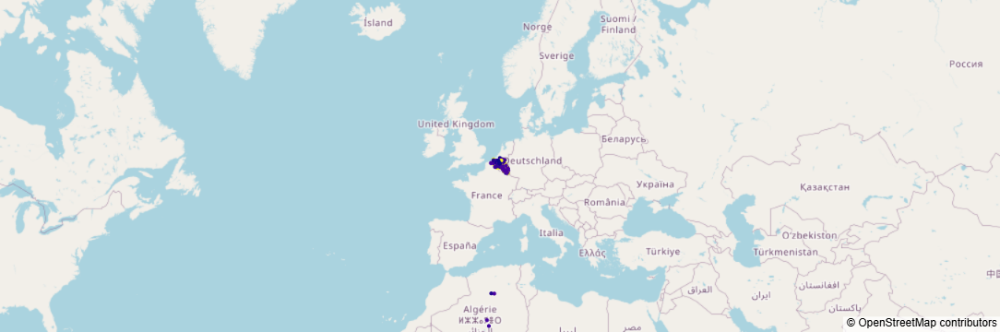

In [12]:
fig = go.Figure()

fig.add_trace(go.Scattermapbox(
    lat=df['approx_lat'],
    lon=df['approx_lon'],
    mode='markers',
    marker=go.scattermapbox.Marker(size=5, color=df['incident_type']),
    text=df['incident_id'],
    hoverinfo='text'
))

fig.update_layout(
    mapbox=dict(
        style="open-street-map",  # Map style (e.g., "carto-positron", "stamen-terrain")
        center=dict(lat=50.5039, lon=4.4699),  # Initial map center
        zoom=2  # Zoom level for the map
    ),
    margin={"r":0,"t":0,"l":0,"b":0},  # Remove default margins
)

fig.show()

Some incidents are located much outside of Belgium e.g. north Africa. We assume that there was a mistake in the geographical coordinates and keep the data since the dataset size is quite small

We can also see that the different incident types are randomly distributed in Belgium. Each color is a different incident type. Lastly, the longitude and latitude of the incidents concerns the start of the route and thus is not very useful.

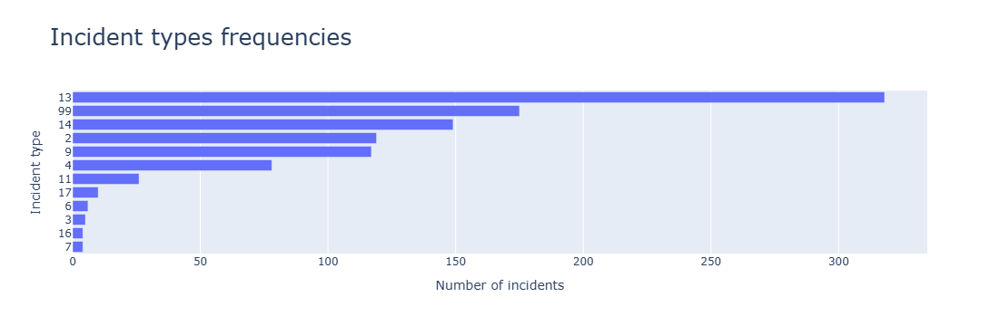

In [14]:
frequency_counts = df['incident_type'].value_counts().iloc[::-1] #reverse order
fig = go.Figure(go.Bar(
            y=frequency_counts.index.astype(str),
            x=frequency_counts.values,
            orientation='h'))

fig.update_layout(title=dict(text='Incident types frequencies',
                             font=dict(size=25)),
                xaxis_title="Number of incidents",
                yaxis_title="Incident type",)
    
fig.show()

The dataset is heavily imbalanced. There are at least 5 minority classes from the 12 total classes

Now we can check how many of the incidents concern one or multiple vehicles:

In [17]:
train_number_dict = {}
counter = 0 
for row_list in df['vehicles_sequence']:
    number_trains = len(set(row_list))
    # check if there is no value for particular dictionary value
    if not train_number_dict.get(number_trains):
        train_number_dict[number_trains] = 0
    train_number_dict[number_trains] += 1
    counter += 1
print("Numbers: " + str(train_number_dict))
print("Percentages: " + str({key: value / counter * 100 for key, value in train_number_dict.items()}))

Numbers: {1: 419, 2: 432, 3: 155, 4: 5}
Percentages: {1: 41.44411473788329, 2: 42.72997032640949, 3: 15.33135509396637, 4: 0.4945598417408506}


In [18]:
# Transform to set to remove duplicates and then calculate number of unique items of set
df['number_vehicles'] = df['vehicles_sequence'].apply(set).apply(len)

We can see the percentages of incidents that consist of 1 vehicle, 2 vehicles, 3 vehicles and 4 vehicles

Next we can analyze the events sequence. Let's create a visual with the total frequencies of each event type:

Total unique values of event types: 917


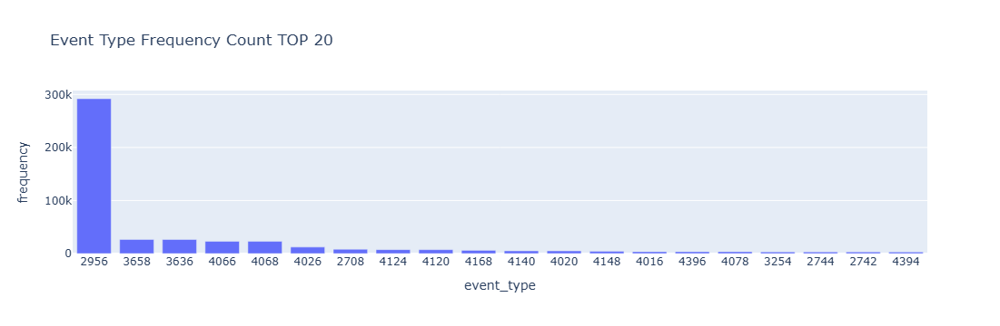

In [21]:
events_sequence_dict = {}
for row_list in df['events_sequence']:
    for event in row_list:
        # check if there is no value for particular dictionary value
        if not events_sequence_dict.get(event):
            events_sequence_dict[event] = 0
        events_sequence_dict[event] += 1
sorted_dict = dict(sorted(events_sequence_dict.items(), key=lambda item: item[1], reverse=True))
# Convert the sorted dictionary to a DataFrame
sorted_events_freq_df = pd.DataFrame(list(sorted_dict.items()), columns=['event_type', 'frequency'])
print('Total unique values of event types: ' + str(sorted_events_freq_df.shape[0]))
# Cast the 'event_type' column to string
sorted_events_freq_df['event_type'] = sorted_events_freq_df['event_type'].astype(str)
# Create a bar plot using Plotly Express
fig = px.bar(sorted_events_freq_df.head(20), x='event_type', y='frequency', title='Event Type Frequency Count TOP 20')
# Show the plot
fig.show()

Checking the visualization we can easily understand that event type $2956$ happens very often compared to any of the other events. Knowing that there are $1011$ unique event sequences, the event type $2956$ repeats itself multiple times in some event sequences
Also, there are in total $917$ unique different event types that occur at least one time in this dataset. 

This visualization does not take into account the event sequence. Now we will analyze the percentage of each event type appearing at least once in an event sequence:

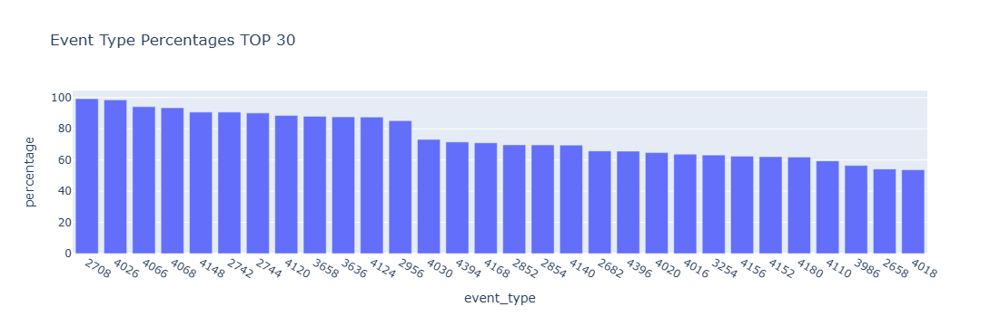

In [24]:
events_types_dict = {}
for row_list in df['events_sequence']:
    unique_events = set(row_list)
    for event in unique_events:
        if not events_types_dict.get(event):
            events_types_dict[event] = 0
        events_types_dict[event] += 1
sorted_dict = dict(sorted(events_types_dict.items(), key=lambda item: item[1], reverse=True))
# Convert the sorted dictionary to a DataFrame
sorted_events_perc_df = pd.DataFrame(list(sorted_dict.items()), columns=['event_type', 'frequency'])
sorted_events_perc_df['percentage'] = sorted_events_perc_df['frequency'] / df.shape[0] * 100
# Cast the 'event_type' column to string
sorted_events_perc_df['event_type'] = sorted_events_perc_df['event_type'].astype(str)
# Create a bar plot using Plotly Express
fig = px.bar(sorted_events_perc_df.head(30), x='event_type', y='percentage', title='Event Type Percentages TOP 30')
# Show the plot
fig.show()

We can see that multiple event types appear in more than 90% of the event sequences. This shows that some event types do not provide a lot of information on their own
- Potentially, the sequential pairing of event types could be more useful in extracting information for the incident type. This is to be explored with association rules.
- Also, potentially some event types that appear less often provide more valuable information on the incident type than the ones that appear most of the times

Now we can explore the basic statistics for the attribute `seconds_to_incident_sequence`:

In [27]:
all_times = []
intervals = []
for row_list in df['seconds_to_incident_sequence']:
    all_times.extend(row_list)
    # Calculate the intervals (differences)
    intervals_current_row = [row_list[i] - row_list[i - 1] for i in range(1, len(row_list))]
    intervals.extend(intervals_current_row)
print("Min time: " + str(min(all_times)))
print("Max time: " + str(max(all_times)))
print("Mean interval: " + str(np.mean(intervals)))
print("Median interval: " + str(np.median(intervals)))

Min time: -14400
Max time: 3600
Mean interval: 27.307959202682564
Median interval: 13.0


Now we can check the frequencies of each event over time, we will create bins of 10 minutes each:

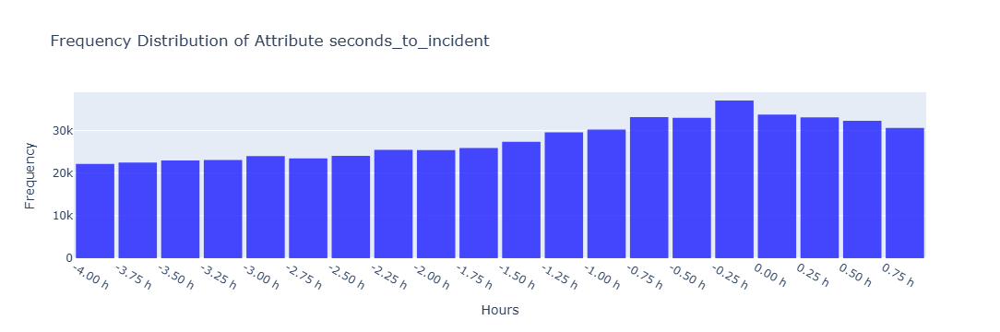

In [29]:
interval_in_plot = 60*15 # transforming seconds to minutes
# Create a histogram using Plotly
fig = go.Figure(data=[go.Histogram(
    x=all_times,
    xbins=dict(
        start=-14400,  # Start of the bins
        end=3600,     # End of the bins
        size=interval_in_plot  # Size of each bin
    ),
    marker=dict(color='blue'),
    opacity=0.7
)])

# Update layout
fig.update_layout(
    title='Frequency Distribution of Attribute seconds_to_incident',
    xaxis_title='Hours',
    yaxis_title='Frequency',
    bargap=0.1  # Gap between bars
)

# Update x-axis ticks to show hours
# Convert ticks to hours (3600 seconds in an hour)
tickvals = np.arange(-14400, 3600, interval_in_plot)  # original tick values in seconds
ticktext = [f"{val/3600:.2f} h" for val in tickvals]  # convert to hours
# Update the x-axis
fig.update_xaxes(tickvals=tickvals, ticktext=ticktext)

# Show the plot
fig.show()

The distribution resembles a lot the normal distribution without the values for the right tail. We can see a peak of frequencies right before $0$ which is the actual time of the incident taking place

## Sorting of events chronologically
Let's check the `events_sequence`, `vehicles_sequence`, `seconds_to_incident_sequence` of an incident with multiple vehicles. Unfortunately, the seconds are not ordered which means that the various lists do not have the events in a ordered chronological way but they are only ordered for the same vehicles. Meaning seconds are ordered for the first vehicles and then right after follow the ordered seconds for the second vehicle and so on. We can see that in an example with the second incident :

In [32]:
pd.DataFrame({
        'vehicles_sequence': df.loc[1, 'vehicles_sequence'],
        'seconds_to_incident_sequence': df.loc[1, 'seconds_to_incident_sequence'],
        'events_sequence': df.loc[1, 'events_sequence'],
    })

,vehicles_sequence,seconds_to_incident_sequence,events_sequence
0,526,-8573,2744
1,526,-8573,4148
2,526,-8032,4394
3,526,-8032,1566
4,526,-8032,1570
5,526,-7859,4396
6,526,-6146,3634
7,526,-5862,4124
8,526,-5651,2956
9,526,-5634,2956


We will order all seconds to the actual chronological order and together with that we will order correspondingly all the other list attributes since those are connected to the particular timestamp (seconds). For example, the lists `seconds_to_incident_sequence` [-5, -1, 1] and `events_sequence` [4394, 1566, 1570] mean that:
- The event 4394 happened -5 sec before the incident
- The event 1566 happened -1 sec before the incident
- The event 1570 happened 1 sec after the incident

The idea for doing this is that we will try to create new attributes that will contains specific information right before the incident happened (time: 0 sec). For multi-vehicle incidents that would be possible since those were not sorted chronologically:

In [34]:
# Function to sort seconds_to_incident_sequence and reorder other columns accordingly
def sort_and_reorder(row):
    # Sort column and get the sorted indices while keeping the current order for equal elements
    sorted_indices = np.lexsort((np.arange(len(row['seconds_to_incident_sequence'])), row['seconds_to_incident_sequence']))
    
    # Apply the sorted indices to all desired columns
    sorted_seconds = [row['seconds_to_incident_sequence'][i] for i in sorted_indices]
    reordered_vehicles = [row['vehicles_sequence'][i] for i in sorted_indices]
    reordered_events = [row['events_sequence'][i] for i in sorted_indices]
    reordered_speed = [row['train_kph_sequence'][i] for i in sorted_indices]
    reordered_dj_ac = [row['dj_ac_state_sequence'][i] for i in sorted_indices]
    reordered_dj_dc = [row['dj_dc_state_sequence'][i] for i in sorted_indices]
       
    
    return pd.Series([sorted_seconds, reordered_vehicles, reordered_events, reordered_speed,
                     reordered_dj_ac, reordered_dj_dc],
                     index=['seconds_to_incident_sequence', 'vehicles_sequence', 'events_sequence',
                               'train_kph_sequence', 'dj_ac_state_sequence', 'dj_dc_state_sequence'])
df[['seconds_to_incident_sequence', 'vehicles_sequence', 'events_sequence',
   'train_kph_sequence', 'dj_ac_state_sequence', 'dj_dc_state_sequence']] =df.apply(sort_and_reorder, axis=1)

## Emergency breaking
It was said that one event code is connected to emergency breaking.

In order to decode which code corresponds to emergency breaking, we need to transform the data columns `seconds_to_incident_sequence`, `train_kph_sequence`, calculate the change of speed and change of time for consecutive events and find the deceleration. Of course, if the time difference is large the deceleration might not be accurate but that is easy to filter once we have calculated the deceleration table:

In [42]:
# Create deceleration df to contain all the results
deceleration_df = pd.DataFrame(columns=['time', 'speed', 'events_sequence', 'delta_speed', 'delta_time', 'deceleration','incident_type'])
# For every incident
for index_num in range(df.shape[0]):
    temp = pd.DataFrame({
        'time': df.loc[index_num, 'seconds_to_incident_sequence'],
        'speed': df.loc[index_num, 'train_kph_sequence'],
        'events_sequence': df.loc[index_num, 'events_sequence'],
        'incident_type': df.loc[index_num, 'incident_type']
    })
    # Calculate the change in speed and change in time
    temp['delta_speed'] = (temp['speed'].diff()) / 3.6  # Speed difference between successive times converted to meter per seconds
    temp['delta_time'] = temp['time'].diff()    # Time difference between successive times
    
    # Calculate deceleration (deceleration = -delta_speed / delta_time)
    temp['deceleration'] = -temp['delta_speed'] / temp['delta_time']
    # Append the results to the deceleration dataframe
    deceleration_df = pd.concat([deceleration_df, temp], ignore_index=True).copy()

C:\Users\stef4\AppData\Local\Temp\ipykernel_9480\1877460137.py:18: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



Now we can filter the results to include only deceleration values over 1, change of time less than 10, and final speed equal to 0, since an emergency breaking would makes sense when a train comes to a full stop:

In [45]:
pd.options.display.max_rows = 10

deceleration_df.loc[(deceleration_df.deceleration > 1) & (deceleration_df.delta_time <10)
        & (deceleration_df.delta_time >0) & (deceleration_df.speed == 0)]

,time,speed,events_sequence,delta_speed,delta_time,deceleration,incident_type
634,27,0.0,4080,-6.138889,6.0,1.023148,13
1012,-3053,0.0,2686,-1.388889,1.0,1.388889,14
2111,-7360,0.0,3636,-9.444444,4.0,2.361111,11
2204,-6297,0.0,2708,-26.333333,5.0,5.266667,11
5530,103,0.0,4080,-8.527778,8.0,1.065972,2
...,...,...,...,...,...,...,...
557622,-3075,0.0,4068,-21.166667,7.0,3.023810,2
557629,-3032,0.0,3640,-30.027778,9.0,3.336420,2
557764,-1951,0.0,4068,-10.111111,9.0,1.123457,2
557768,-1925,0.0,3636,-9.416667,5.0,1.883333,2


Looks like the are some crazy high deceleration values for some timestamps, which can not be real:
- Those values arise after resorting the dataframe.
- Probably the train vehicles were not united the whole duration.
- In fact those high deceleration values always appear far before or after the incident

 Thus it is better to use the original dataset without resorting the speeds of the vehicles. Also, the deceleration is in meter per square seconds which corresponds to much Let's see below:

In [47]:
deceleration_df.loc[(deceleration_df.deceleration > 20) & (deceleration_df.delta_time <10)
        & (deceleration_df.delta_time >0)]

,time,speed,events_sequence,delta_speed,delta_time,deceleration,incident_type
21802,-12858,0.0,4078,-24.416667,1.0,24.416667,2
22172,-7533,0.0,4168,-24.861111,1.0,24.861111,2
22204,-7330,0.0,2886,-24.555556,1.0,24.555556,2
22414,-3925,0.1,4066,-21.611111,1.0,21.611111,2
22634,-1251,0.0,4066,-20.277778,1.0,20.277778,2
...,...,...,...,...,...,...,...
557194,-8322,1.6,4068,-21.527778,1.0,21.527778,2
557196,-8320,0.0,2686,-21.833333,1.0,21.833333,2
557321,-6609,29.3,2956,-29.555556,1.0,29.555556,2
557712,-2379,0.1,4066,-23.583333,1.0,23.583333,2


Now we reload the dataframe, to keep the original sorting and redo the sorting:

In [52]:
df = pd.read_csv('sncb_data_challenge.csv', delimiter=';')
df.events_sequence = df.events_sequence.apply(ast.literal_eval) #transforming column saved as string to list of elements
df.seconds_to_incident_sequence = df.seconds_to_incident_sequence.apply(ast.literal_eval) #transforming column saved as string to list of elements
df.train_kph_sequence = df.train_kph_sequence.apply(ast.literal_eval) #transforming column saved as string to list of elements
df.dj_ac_state_sequence = df.dj_ac_state_sequence.apply(ast.literal_eval)
df.dj_dc_state_sequence = df.dj_dc_state_sequence.apply(ast.literal_eval)
df.vehicles_sequence = df.vehicles_sequence.apply(ast.literal_eval)

# Create deceleration df to contain all the results
deceleration_df = pd.DataFrame(columns=['time', 'speed', 'events_sequence', 'delta_speed', 'delta_time', 'deceleration','incident_type'])
# For every incident
for index_num in range(df.shape[0]):
    temp = pd.DataFrame({
        'time': df.loc[index_num, 'seconds_to_incident_sequence'],
        'speed': df.loc[index_num, 'train_kph_sequence'],
        'events_sequence': df.loc[index_num, 'events_sequence'],
        'incident_type': df.loc[index_num, 'incident_type']
    })
    # Calculate the change in speed and change in time
    temp['delta_speed'] = (temp['speed'].diff()) / 3.6  # Speed difference between successive times converted to meter per seconds
    temp['delta_time'] = temp['time'].diff()    # Time difference between successive times
    
    # Calculate deceleration (deceleration = -delta_speed / delta_time)
    temp['deceleration'] = -temp['delta_speed'] / temp['delta_time']
    # Append the results to the deceleration dataframe
    deceleration_df = pd.concat([deceleration_df, temp], ignore_index=True).copy()

C:\Users\stef4\AppData\Local\Temp\ipykernel_9480\428815412.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



Checking the events, we can see that the code that comes up most of the times is `4080`. Again, we only include deceleration values over 1, change of time less than 10, and final speed equal to 0, since an emergency breaking would makes sense when a train comes to a full stop

In [54]:
deceleration_df.loc[(deceleration_df.deceleration > 1) & (deceleration_df.delta_time <10)
        & (deceleration_df.delta_time >0) & (deceleration_df.speed == 0)].events_sequence.value_counts()

events_sequence
4080    36
4066     5
4068     5
2688     3
2686     2
4004     1
4002     1
Name: count, dtype: int64

Let's see which event code has the highest average deceleration. Again code `4080` has the highest statistic, this time mean :

In [56]:
codes = deceleration_df.loc[(deceleration_df.deceleration > 1) & (deceleration_df.delta_time <10)
        & (deceleration_df.delta_time > 0)].events_sequence.value_counts().index[:5]
for code in codes:
    decelation_current = deceleration_df.loc[(deceleration_df.events_sequence == code) & 
                        (deceleration_df.deceleration > -999) & (deceleration_df.deceleration < 999)].deceleration.mean()
    print('Code: ' + str(code) + ' deceleration of ' + str(decelation_current))

Code: 2956 deceleration of -0.027248583180364692
Code: 4080 deceleration of 0.3739321401337426
Code: 4066 deceleration of 0.24501662949103992
Code: 4068 deceleration of 0.25174332306364205
Code: 2686 deceleration of 0.23880561894496713


Also, we can check the frequency of codes where there was an acceleration (negative deceleration). It is for sure that during an emergency breaking there will not be any acceleration. Indeed the codes `4066` and `4068` have some occurrences with acceleration for delta time less than 10. As a result we can confidently say that code `4080` is most likely  the code of emergency breaking.

In [183]:
deceleration_df.loc[(deceleration_df.delta_time < 10) & (deceleration_df.deceleration < -0.5) & 
    (deceleration_df.events_sequence >= 4066) & (deceleration_df.events_sequence <= 4068)].events_sequence.value_counts()[:20]

events_sequence
4068    38
4066    27
Name: count, dtype: int64

Now we can see the frequency of the incidents that the code `4080` appeared:

In [62]:
df[df['events_sequence'].apply(lambda x: 4080 in x)].incident_type.value_counts()

incident_type
13    174
2      45
14     20
4      20
9      19
99     18
11      3
17      2
16      1
Name: count, dtype: int64

#### Conclusion
Looks like the code `4080` is connected to emergency breaking due to the frequency of its cases and the highest average deceleration. Also, cases where deceleration was 0 were checked. Many times, there was an event short before the event `4080` (a second or less) which led to deceleration being 0, since we only consider sequentially. There was no acceleration found for an event of that particular code.

Plotting the results:

In [153]:
results_frequency = deceleration_df.loc[(deceleration_df.deceleration > 1) & (deceleration_df.delta_time <10)
            & (deceleration_df.delta_time >0) & (deceleration_df.speed == 0)].groupby('events_sequence'\
            ).agg(Frequency=('deceleration', 'count')
            ).reset_index().sort_values(by='Frequency', ascending=False)
results_frequency['events_sequence'] = results_frequency['events_sequence'].astype(str)

results_deceleration = deceleration_df.loc[(deceleration_df.deceleration > -999) & (deceleration_df.deceleration < 999)].groupby('events_sequence'\
            ).agg( Average_Deceleration=('deceleration', 'mean')
            ).reset_index()
results_deceleration['events_sequence'] = results_deceleration['events_sequence'].astype(str)

results = results_frequency.merge(results_deceleration, on='events_sequence').head(6)

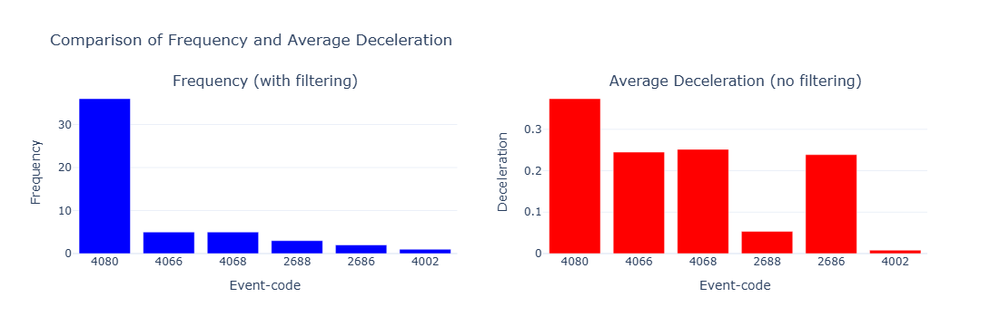

In [179]:
# Create subplots
fig = make_subplots(
    rows=1, cols=2,  # One row, two columns
    subplot_titles=("Frequency (with filtering)", "Average Deceleration (no filtering)")
)

# Add frequency bar plot to the first subplot
fig.add_trace(
    go.Bar(x=results.events_sequence, y=results.Frequency, marker_color='blue', name='Frequency'),
    row=1, col=1
)

# Add deceleration bar plot to the second subplot
fig.add_trace(
    go.Bar(x=results.events_sequence, y=results.Average_Deceleration, marker_color='red', name='Average Deceleration'),
    row=1, col=2
)

# Update layout
fig.update_layout(
    title="Comparison of Frequency and Average Deceleration",
    template="plotly_white",
    showlegend=False  # Turn off legend as it's unnecessary with subplot titles
)

# Add axis titles for both subplots
fig.update_xaxes(title_text="Event-code", row=1, col=1)  # Title for the first subplot's x-axis
fig.update_xaxes(title_text="Event-code", row=1, col=2)  # Title for the second subplot's x-axis
fig.update_yaxes(title_text="Frequency", row=1, col=1)  # Title for the first subplot's y-axis
fig.update_yaxes(title_text="Deceleration", row=1, col=2)  # Title for the second subplot's y-axis

# Show the figure
fig.show()